# Limpieza y preprocesamiento — Dow Jones (Reto 9)

**Dataset de entrada:** `Datos/DowJones/*.csv` (26 ficheros, uno por acción, formato `marketstack`).

**Objetivo de este script:** dejar un dataset único, limpio, con frecuencia homogénea y sin missings,
que sirva de entrada para la selección de la cartera (Sección 3 de la descripción técnica).

Pasos (siguiendo el procedimiento visto en clase — Procesamiento de Series Temporales):
1. Carga y unificación
2. Duplicados y orden temporal
3. Comprobación de calidad / coherencia OHLC
4. Homogenización de la frecuencia muestral
5. Tratamiento de missings
6. Completado con Yahoo Finance
7. Análisis descriptivo
8. Guardado del dataset limpio

In [3]:
import pandas as pd
import os


In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

## 1. Carga y unificación de los datos

In [5]:
# Ruta relativa dentro del repositorio (ajustar si la estructura de carpetas es otra)
RUTA_DATOS = os.path.join("Datos", "DowJones")

lista_df = []
for nombre_archivo in os.listdir(RUTA_DATOS):
    if nombre_archivo.endswith(".csv"):
        temp = pd.read_csv(os.path.join(RUTA_DATOS, nombre_archivo))
        lista_df.append(temp)

df = pd.concat(lista_df, ignore_index=True)
df["date"] = pd.to_datetime(df["date"], utc=True)

print(f"Archivos leidos: {len(lista_df)}")
print(f"Filas totales:   {len(df)}")
print(f"Simbolos:        {df['symbol'].nunique()}")
df.dtypes

Archivos leidos: 26
Filas totales:   2744418
Simbolos:        26


open                    float64
high                    float64
low                     float64
last                    float64
close                   float64
volume                  float64
date        datetime64[us, UTC]
symbol                      str
exchange                    str
dtype: object

## 2. Duplicados y orden temporal

Puede haber registros repetidos (mismo símbolo + misma fecha) si algún fichero se
solapa. Los eliminamos y ordenamos la serie cronológicamente por símbolo, que es
el orden que necesitaremos para interpolar y para el resampling posterior.

In [37]:
df = df.drop_duplicates(subset=["symbol", "date"])
df = df.sort_values(["symbol", "date"]).reset_index(drop=True)
print("Filas tras quitar duplicados:", len(df))

Filas tras quitar duplicados: 2744418


## 3. Comprobación de calidad / coherencia OHLC

Antes de imputar nada, comprobamos que los precios sean financieramente coherentes:
`high` no puede ser menor que `low`, y ningún precio puede ser negativo o cero.
Si aparecieran filas incoherentes, se marcarían como missing (NaN) para que el
tratamiento de missings del punto 5 las repare, en vez de dejarlas colar como
datos válidos.

In [38]:
cond_incoherente = (
    (df["high"] < df["low"])
    | (df["open"] <= 0) | (df["high"] <= 0) | (df["low"] <= 0)
    | (df["close"] <= 0)
)
print("Filas con incoherencias OHLC:", cond_incoherente.sum())

cols_precio = ["open", "high", "low", "close", "last"]
df.loc[cond_incoherente, cols_precio] = np.nan

Filas con incoherencias OHLC: 0


## 4. Homogenización de la frecuencia muestral

Los datos vienen a frecuencia **intradía e irregular** (mayoritariamente cada 5
minutos, pero con huecos de tamaño variable). Además, comprobamos que **no todas
las acciones cubren el mismo periodo**: 6 de las 26 empiezan en 2018, y las 20
restantes solo tienen datos desde el 29/05/2020. Esto es importante tenerlo en
cuenta a la hora de elegir la cartera (sección 3), porque limita el histórico
disponible para calcular volatilidades/correlaciones si se mezclan acciones de
ambos grupos.

Para trabajar con las series (cartera, volatilidad, Montecarlo) necesitamos una
frecuencia homogénea. Agregamos los datos intradía a **frecuencia diaria (días
hábiles)**, construyendo un OHLC estándar por día y símbolo:
- `open`  = primer valor del día
- `high`  = máximo del día
- `low`   = mínimo del día
- `close` / `last` = último valor del día
- `volume` = suma del volumen del día

In [39]:
def resample_symbol(g):
    g = g.set_index("date").sort_index()
    return pd.DataFrame({
        "open":   g["open"].resample("B").first(),
        "high":   g["high"].resample("B").max(),
        "low":    g["low"].resample("B").min(),
        "last":   g["last"].resample("B").last(),
        "close":  g["close"].resample("B").last(),
        "volume": g["volume"].resample("B").sum(),
    })

daily_list = []
for symbol, g in df.groupby("symbol"):
    d = resample_symbol(g)
    d["symbol"] = symbol
    d["exchange"] = g["exchange"].iloc[0]
    daily_list.append(d)

df_daily = pd.concat(daily_list).reset_index()
print("Filas tras homogenizar a frecuencia diaria:", len(df_daily))
df_daily.groupby("symbol")["date"].agg(["min", "max", "count"])

Filas tras homogenizar a frecuencia diaria: 10492


,min,max,count
symbol,,,
AAPL,2018-06-06 00:00:00+00:00,2021-07-01 00:00:00+00:00,802
AMGN,2020-05-29 00:00:00+00:00,2021-07-01 00:00:00+00:00,285
AXP,2020-05-29 00:00:00+00:00,2021-07-01 00:00:00+00:00,285
BA,2020-05-29 00:00:00+00:00,2021-07-01 00:00:00+00:00,285
CAT,2018-06-11 00:00:00+00:00,2021-07-01 00:00:00+00:00,799
CRM,2020-05-29 00:00:00+00:00,2021-07-01 00:00:00+00:00,285
CSCO,2020-05-29 00:00:00+00:00,2021-07-01 00:00:00+00:00,285
CVX,2020-05-29 00:00:00+00:00,2021-07-01 00:00:00+00:00,285
DIS,2020-05-29 00:00:00+00:00,2021-07-01 00:00:00+00:00,285


## 5. Tratamiento de missings

Tras el resampling a días hábiles, los NaN que aparecen corresponden en su
mayoría a **festivos de mercado** (el índice de días hábiles incluye días en los
que la bolsa estuvo cerrada, p.ej. Acción de Gracias, Navidad...), no a errores
de captura. Para ese caso el método adecuado es **LOCF (Last Observation Carried
Forward)**: el precio de un día festivo es, por definición, el mismo que el del
último día en que cotizó. Usamos `bfill` como respaldo solo para el primer
registro de cada serie (si empezara con NaN, cosa que no debería pasar tras el
resample).

El volumen en un día sin sesión es 0 por definición (no se rellena con el
último valor).

In [40]:
print("Missings antes de imputar:")
print(df_daily.isna().sum())

for col in ["open", "high", "low", "last", "close"]:
    df_daily[col] = df_daily.groupby("symbol")[col].transform(lambda x: x.ffill().bfill())

df_daily["volume"] = df_daily["volume"].fillna(0)

print("\nMissings despues de imputar (debe ser todo 0):")
print(df_daily.isna().sum())

Missings antes de imputar:
date           0
open         141
high         141
low          141
last        3492
close        295
volume         0
symbol         0
exchange       0
dtype: int64

Missings despues de imputar (debe ser todo 0):
date        0
open        0
high        0
low         0
last        0
close       0
volume      0
symbol      0
exchange    0
dtype: int64


## 6. Completado con datos de Yahoo Finance

El índice Dow Jones tiene 30 componentes y el dataset facilitado solo trae 26.
Comparando contra la composición del Dow 30 identificamos los 4 símbolos que
faltan: **HON, VZ, WBA, WMT**. Los descargamos con `yfinance` para completar el
dataset, con el mismo esquema de columnas.

> **Nota:** esta celda necesita conexión a internet (Yahoo Finance) para
> ejecutarse.

In [46]:
# pip install yfinance   # si no lo tienes instalado
import yfinance as yf

TICKERS_DOW30 = {
    "AAPL","AMGN","AXP","BA","CAT","CRM","CSCO","CVX","DIS","DOW","GS","HD",
    "HON","IBM","INTC","JNJ","JPM","KO","MCD","MMM","MRK","MSFT","NKE","PG",
    "TRV","UNH","V","VZ","WBA","WMT",
}
simbolos_actuales = set(df_daily["symbol"].unique())
simbolos_faltantes = sorted(TICKERS_DOW30 - simbolos_actuales)
print("Simbolos que faltan y se completan con yfinance:", simbolos_faltantes)

fecha_ini = df_daily["date"].min().date()
fecha_fin = df_daily["date"].max().date()

nuevos = []
for simbolo in simbolos_faltantes:
    hist = yf.download(simbolo, start=fecha_ini, end=fecha_fin, progress=False, auto_adjust=False)
    if hist.empty:
        print(f"Aviso: no se ha podido descargar {simbolo}, se omite.")
        continue
    if isinstance(hist.columns, pd.MultiIndex):
        # yfinance moderno devuelve columnas (Precio, Ticker) al descargar 1 solo simbolo
        hist.columns = hist.columns.get_level_values(0)
    hist = hist.reset_index().rename(columns={
        "Date": "date", "Open": "open", "High": "high",
        "Low": "low", "Close": "close", "Volume": "volume",
    })
    hist["last"] = hist["close"]
    hist["symbol"] = simbolo
    hist["exchange"] = "YFINANCE"
    hist["date"] = pd.to_datetime(hist["date"], utc=True)
    nuevos.append(hist[["open", "high", "low", "last", "close", "volume", "date", "symbol", "exchange"]])

if nuevos:
    df_daily = pd.concat([df_daily] + nuevos, ignore_index=True)
    df_daily = df_daily.sort_values(["symbol", "date"]).reset_index(drop=True)

print("Filas totales tras completar con yfinance:", len(df_daily))
print("Simbolos totales:", df_daily["symbol"].nunique())

Simbolos que faltan y se completan con yfinance: ['HON', 'VZ', 'WBA', 'WMT']


HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: WBA"}}}
$WBA: possibly delisted; no timezone found

1 Failed download:
['WBA']: possibly delisted; no timezone found


Aviso: no se ha podido descargar WBA, se omite.
Filas totales tras completar con yfinance: 12811
Simbolos totales: 29


## 7. Análisis descriptivo

Estadísticos básicos y visualización rápida de las series, tal y como pide el
enunciado ("realicen un análisis descriptivo") y el criterio de evaluación de
Data Science ("Análisis fundamentado de las series temporales").

In [43]:
df_daily.groupby("symbol")["close"].describe()

,count,mean,std,min,25%,50%,75%,max
symbol,,,,,,,,
AAPL,802.0,210.609419,80.945742,106.840,135.025,199.105,256.245,506.090
AMGN,285.0,239.451729,10.919837,216.380,230.320,239.640,248.630,260.950
AXP,285.0,122.241912,23.480919,90.570,101.440,118.670,144.330,169.450
BA,285.0,204.476018,32.895476,144.390,173.280,209.910,233.630,269.190
CAT,799.0,149.513567,34.494475,91.870,128.060,138.220,153.850,244.790
CRM,285.0,224.708614,24.026729,171.440,209.530,225.860,242.740,281.250
CSCO,285.0,46.020893,4.788794,35.690,42.500,45.740,50.010,55.030
CVX,285.0,92.011263,11.432180,66.880,85.330,90.960,103.200,111.560
DIS,285.0,154.567772,28.687048,109.100,125.410,168.170,180.230,201.910


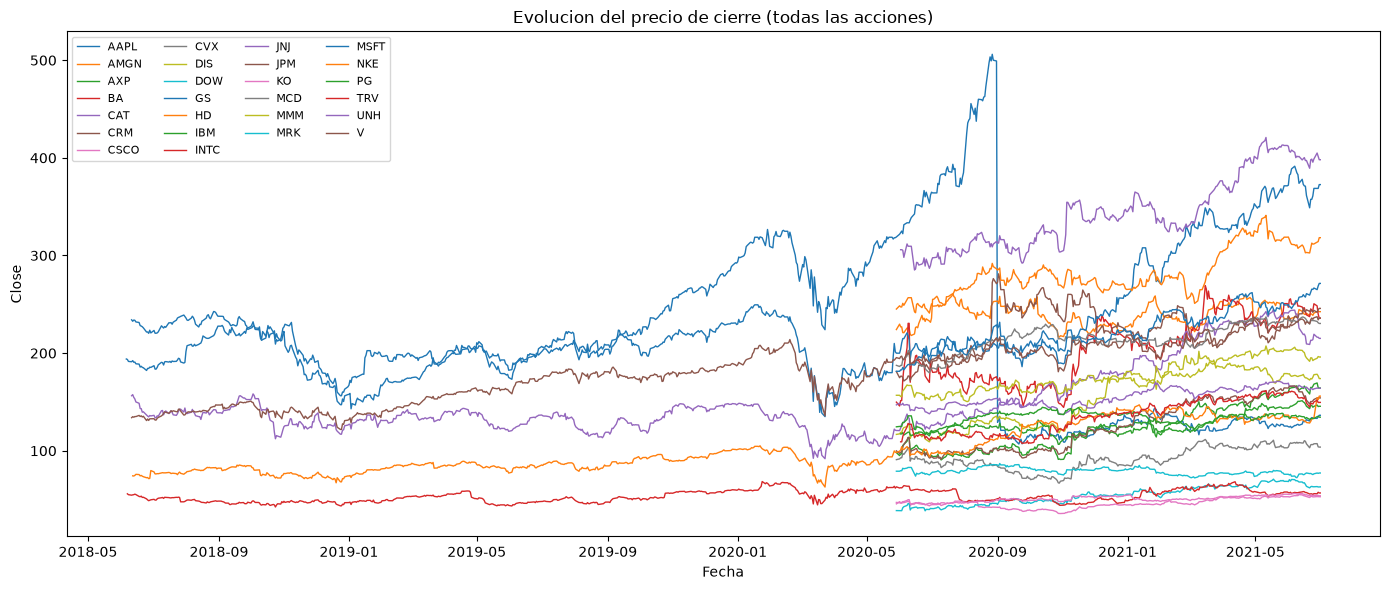

In [44]:
# Evolución del precio de cierre de todas las acciones
fig, ax = plt.subplots(figsize=(14, 6))
for symbol, g in df_daily.groupby("symbol"):
    ax.plot(g["date"], g["close"], label=symbol, linewidth=1)
ax.set_title("Evolucion del precio de cierre (todas las acciones)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Close")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

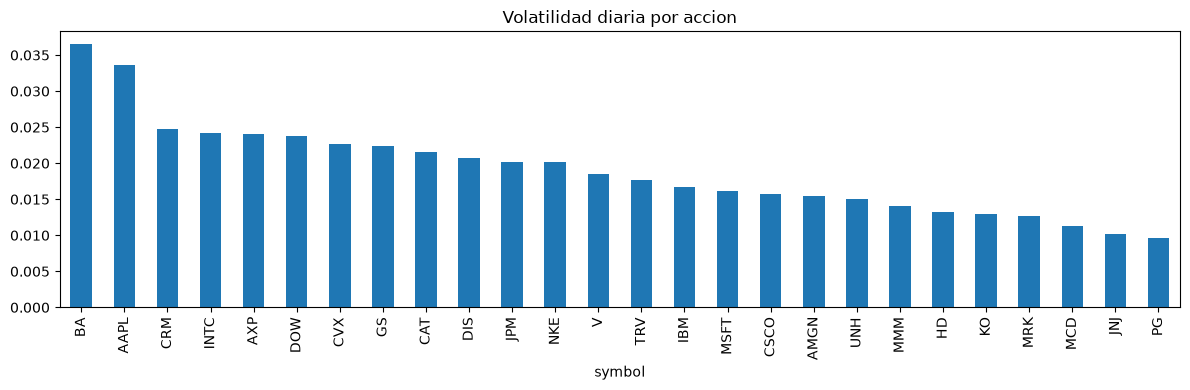

In [45]:
# Volatilidad (desviacion tipica de los retornos diarios) por accion,
# util mas adelante para justificar la seleccion de la cartera (Seccion 3)
retornos = df_daily.pivot(index="date", columns="symbol", values="close").pct_change()
volatilidad = retornos.std().sort_values(ascending=False)
volatilidad.plot(kind="bar", figsize=(12, 4), title="Volatilidad diaria por accion")
plt.tight_layout()
plt.show()

## 8. Guardado del dataset limpio

Guardamos el resultado para que el resto de scripts del proyecto (selección de
cartera, generación de datos sintéticos...) partan de aquí, sin repetir la
limpieza. La carpeta de datos no se sube al repositorio (indicado en las
instrucciones de entrega), así que el csv se guarda localmente.

In [ ]:
RUTA_SALIDA = os.path.join("Datos", "dowjones_limpio.csv")
df_daily.to_csv(RUTA_SALIDA, index=False)
print("Guardado en:", RUTA_SALIDA)